# 1. Preparation


## 1.1. Importing Libraries and Defining Some Constants


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from numpy.random import multivariate_normal
from matplotlib.animation import FuncAnimation
from IPython.display import Image
from abc import ABC, abstractmethod
from scipy.stats import ttest_ind, ttest_ind_from_stats

In [2]:
LOG_DIR = "logs"
FIGURE_DIR = "figures"
GIF_DIR = "gifs"

In [3]:
STUDENT_ID = 23520199
N_TRIALS = 10
POSSIBLE_POP_SIZES = [8, 16, 32, 64, 128]
POSSIBLE_DIMS = [2, 10]
POSSIBLE_MAX_EVALS = [dim * 1000 for dim in POSSIBLE_DIMS]
GRAPH_N = 32  # chosen pop size for convergence graph

## 1.2. Defining the Objective Functions


In [4]:
class ObjectiveFunc(ABC):

    def __init__(self, value_domain: tuple[int, int]):
        self.value_domain = value_domain

    @abstractmethod
    def get_global_minimum(self, dim: int):
        pass

    @abstractmethod
    def evaluate(self, x: np.ndarray):
        pass

### 1.2.1. Sphere


In [5]:
class SphereFunc(ObjectiveFunc):

    def __init__(self):
        super().__init__(value_domain=(-5.12, 5.12))

    def get_global_minimum(self, dim: int) -> np.ndarray:
        return np.zeros(dim)

    def evaluate(self, x: np.ndarray) -> np.ndarray:
        assert len(x.shape) == 2, "Input must have shape (pop_size, dim)."
        return np.sum(x**2, axis=1)

### 1.2.2. Griewank Function


In [6]:
class GriewankFunc(ObjectiveFunc):
    def __init__(self):
        super().__init__(value_domain=(-600.0, 600.0))

    def get_global_minimum(self, dim: int):
        return np.zeros(dim)

    def evaluate(self, x: np.ndarray):
        assert len(x.shape) == 2, "Input must have shape (pop_size, dim)."
        d = x.shape[1]
        term1 = np.sum(x**2, axis=1) / 4000
        term2 = np.prod(np.cos(x / np.sqrt(np.arange(1, d + 1))), axis=1)
        return term1 - term2 + 1

### 1.2.3. Rosenbrock Function


In [7]:
class RosenbrockFunc(ObjectiveFunc):
    def __init__(self):
        super().__init__(value_domain=(-5.0, 10.0))

    def get_global_minimum(self, dim: int):
        return np.ones(dim)

    def evaluate(self, x: np.ndarray):
        assert len(x.shape) == 2, "Input must have shape (pop_size, dim)."
        term1 = 100 * (x[:, 1:] - x[:, :-1] ** 2) ** 2
        term2 = (x[:, :-1] - 1) ** 2
        return np.sum(term1 + term2, axis=1)

### 1.2.4. Rastrigin Function


In [8]:
class RastriginFunc(ObjectiveFunc):
    def __init__(self):
        super().__init__(value_domain=(-5.12, 5.12))

    def get_global_minimum(self, dim: int):
        return np.zeros(dim)

    def evaluate(self, x: np.ndarray):
        assert len(x.shape) == 2, "Input must have shape (pop_size, dim)."
        d = x.shape[1]
        term1 = x**2
        term2 = 10 * np.cos(2 * np.pi * x)
        return 10 * d + np.sum(term1 - term2, axis=1)

### 1.2.5. Ackley Function


In [9]:
class AckleyFunc(ObjectiveFunc):
    def __init__(self):
        super().__init__(value_domain=(-32.768, 32.768))
        self.a = 20
        self.b = 0.2
        self.c = 2 * np.pi

    def get_global_minimum(self, dim: int):
        return np.zeros(dim)

    def evaluate(self, x: np.ndarray):
        assert len(x.shape) == 2, "Input must have shape (pop_size, dim)."
        term1 = self.a * np.exp(-self.b * np.sqrt(np.mean(x**2, axis=1)))
        term2 = np.exp(np.mean(np.cos(self.c * x), axis=1))
        return -term1 - term2 + self.a + np.exp(1)

## 1.3. Other stuff


In [10]:
obj_funcs: dict[str, ObjectiveFunc] = {
    "Sphere": SphereFunc(),
    "Griewank": GriewankFunc(),
    "Rosenbrock": RosenbrockFunc(),
    "Rastrigin": RastriginFunc(),
    "Ackley": AckleyFunc(),
}

In [11]:
convergence_graph = {
    (obj_func_name, dim): {"DE": (), "GA": ()}
    for obj_func_name in obj_funcs.keys()
    for dim in POSSIBLE_DIMS
}

In [12]:
statistic_table = {
    (obj_func_name, dim, N): {"DE": {}, "GA": {}}
    for obj_func_name in obj_funcs.keys()
    for dim in POSSIBLE_DIMS
    for N in POSSIBLE_POP_SIZES
}

In [13]:
def create_gif(
    obj_func_name: str, obj_func: ObjectiveFunc, history: list[np.ndarray], algo: str
):
    fig, ax = plt.subplots(figsize=(8, 8))
    lb, ub = obj_func.value_domain
    x = np.linspace(lb, ub, 100)
    y = np.linspace(lb, ub, 100)
    X, Y = np.meshgrid(x, y)

    pts = np.column_stack([X.ravel(), Y.ravel()])
    Z = obj_func.evaluate(pts).reshape(X.shape)

    contour = ax.contourf(X, Y, Z, levels=50, cmap="viridis", alpha=0.6)
    fig.colorbar(contour, ax=ax)

    opt = obj_func.get_global_minimum(2)
    ax.plot(opt[0], opt[1], "r*", markersize=15, label="Global Optimum")

    scat = ax.scatter([], [], c="blue", s=30, edgecolors="k", label="Population")

    ax.set_xlim(lb, ub)
    ax.set_ylim(lb, ub)
    ax.set_title(f"{algo} on {obj_func_name} (dim=2)")
    ax.legend()

    def init():
        scat.set_offsets(np.empty((0, 2)))
        return (scat,)

    def update(frame):
        pop = history[frame]
        scat.set_offsets(pop)
        ax.set_title(
            f"{algo} on {obj_func_name} (dim=2) - Gen {frame+1}/{len(history)}"
        )
        return (scat,)

    ani = FuncAnimation(
        fig, update, frames=len(history), init_func=init, blit=True, repeat=False
    )

    out_path = Path(GIF_DIR) / f"{obj_func_name}_{algo}.gif"
    out_path.parent.mkdir(parents=True, exist_ok=True)

    ani.save(out_path, writer="pillow", fps=10)
    plt.close(fig)

# 2. Differential Evolution (DE)


In [14]:
def differential_evo(
    obj_func: ObjectiveFunc,
    pop_size: int,
    dim: int,
    max_evals: int,
    F: float = 0.5,  # scaling factor
    CR: float = 0.8,  # crossover rate
    random_seed: int = 42,
    is_logging: bool = False,
    log_filepath: Path | None = None,
    return_history: bool = False,
) -> tuple[list[int], list[float], float, list[np.ndarray]]:
    np.random.seed(random_seed)

    # Initialize population
    lb, ub = obj_func.value_domain
    pop = np.random.uniform(lb, ub, size=(pop_size, dim))

    fitness = obj_func.evaluate(pop)
    evals = pop_size

    best_gen_idx = np.argmin(fitness)
    best_solution = pop[best_gen_idx].copy()
    best_fitness = best_gen_fitness = fitness[best_gen_idx]

    eval_list = [evals]
    fitness_list = [best_gen_fitness]
    pop_history = []

    if return_history:
        pop_history.append(pop.copy())

    while evals < max_evals:
        for i in range(pop_size):
            if evals >= max_evals:
                break

            # Selection of 3 distinct individuals different from i
            idx = np.random.choice(pop_size - 1, size=3, replace=False)
            idx += idx >= i  # skip i
            a, b, c = pop[idx]

            # Mutation
            mutant = a + F * (b - c)
            mutant = np.clip(mutant, lb, ub)

            # Crossover
            cross_points = np.random.rand(dim) < CR
            j_rand = np.random.randint(0, dim)
            cross_points[j_rand] = True

            trial = np.where(cross_points, mutant, pop[i])

            # Evaluation
            trial_fitness = obj_func.evaluate(trial.reshape(1, dim))[0]
            evals += 1

            # Selection for next generation
            if trial_fitness < fitness[i]:
                pop[i] = trial
                fitness[i] = trial_fitness

        best_gen_idx = np.argmin(fitness)
        best_gen_fitness = fitness[best_gen_idx]
        eval_list.append(evals)
        fitness_list.append(best_gen_fitness)

        if return_history:
            pop_history.append(pop.copy())

        if best_gen_fitness < best_fitness:
            best_fitness = best_gen_fitness
            best_solution = pop[best_gen_idx].copy()

    if is_logging:
        with log_filepath.open("a") as f:
            f.write(f"{random_seed},{best_solution},{best_fitness}\n")

    return eval_list, fitness_list, best_fitness, pop_history

In [15]:
for obj_func_name, obj_func in obj_funcs.items():
    for pop_size in POSSIBLE_POP_SIZES:
        for i in range(len(POSSIBLE_DIMS)):
            dim = POSSIBLE_DIMS[i]
            max_evals = POSSIBLE_MAX_EVALS[i]

            fitness_table = []
            best_fitnesses = []

            log_filepath = (
                Path(LOG_DIR)
                / obj_func_name
                / "DE"
                / f"pop{pop_size:03d}"
                / f"dim{dim:02d}.csv"
            )

            log_filepath.parent.mkdir(parents=True, exist_ok=True)
            with log_filepath.open("w") as f:
                f.write(f"random_seed,best_solution,best_fitness\n")

            for trial in range(N_TRIALS):
                random_seed = STUDENT_ID + trial

                eval_list, fitness_list, best_fitness, _ = differential_evo(
                    obj_func=obj_func,
                    pop_size=pop_size,
                    dim=dim,
                    max_evals=max_evals,
                    random_seed=random_seed,
                    is_logging=True,
                    log_filepath=log_filepath,
                )

                best_fitnesses.append(best_fitness)

                if pop_size == GRAPH_N:
                    fitness_table.append(fitness_list)

            statistic_table[(obj_func_name, dim, pop_size)]["DE"] = {
                "mean": np.mean(best_fitnesses),
                "std": np.std(best_fitnesses),
            }

            if pop_size == GRAPH_N:
                fitness_table = np.array(fitness_table)
                eval_list = np.array(eval_list)
                mean = np.mean(fitness_table, axis=0)
                std = np.std(fitness_table, axis=0)
                convergence_graph[(obj_func_name, dim)]["DE"] = (
                    eval_list,
                    mean,
                    std,
                )

# 3. Cross Entropy Method (CEM)


In [16]:
def cross_entropy_method(
    obj_func,
    pop_size: int,
    dim: int,
    max_evals: int,
    rho: float = 0.2,  # Fraction of elites (Ne / N)
    sigma_init: float = 0.2,
    epsilon: float = 1e-4,
    random_seed: int = 42,
    is_logging: bool = False,
    log_filepath: Path | None = None,
    return_history: bool = False,
) -> tuple[list[int], list[float], float, list[np.ndarray]]:
    np.random.seed(random_seed)
    lb, ub = obj_func.value_domain

    # Initialization
    num_elite = max(1, int(pop_size * rho))
    mu = np.random.uniform(lb, ub, size=dim)
    sigma_init *= ub - lb
    Sigma = sigma_init * np.eye(dim)

    # Calculate weights
    weights = np.array(
        [np.log(num_elite + 1) - np.log(i + 1) for i in range(num_elite)]
    )
    weights /= np.sum(weights)

    evals = 0
    best_fitness = float("inf")
    best_solution = None

    eval_list = []
    fitness_list = []
    pop_history = []

    while evals < max_evals:
        # Sample N candidates from N(mu, Sigma)
        pop = np.random.multivariate_normal(mu, Sigma, size=pop_size)
        pop = np.clip(pop, lb, ub)

        if return_history:
            pop_history.append(pop.copy())

        # Handle remaining evaluations bound
        curr_pop_size = min(pop_size, max_evals - evals)
        pop_eval = pop[:curr_pop_size]

        # Evaluate candidates
        fitness = obj_func.evaluate(pop_eval)
        evals += curr_pop_size

        # Update global best tracking
        gen_best_idx = np.argmin(fitness)
        if fitness[gen_best_idx] < best_fitness:
            best_fitness = fitness[gen_best_idx]
            best_solution = pop_eval[gen_best_idx].copy()

        eval_list.append(evals)
        fitness_list.append(best_fitness)

        # Selection
        if curr_pop_size >= num_elite:
            elite_indices = np.argsort(fitness)[:num_elite]
            elites = pop_eval[elite_indices]

            # Store old mu for the Sigma update calculation
            old_mu = mu.copy()

            # Update parameters
            # mu^(t+1) = sum(w_i * z_i)
            mu = np.sum(weights[:, np.newaxis] * elites, axis=0)

            # Sigma^(t+1) = sum(w_i * (z_i - mu_old)(z_i - mu_old)^T) + epsilon * I
            new_Sigma = np.zeros((dim, dim))
            for i in range(num_elite):
                diff = (elites[i] - old_mu).reshape(-1, 1)
                new_Sigma += weights[i] * (diff @ diff.T)

            Sigma = new_Sigma + epsilon * np.eye(dim)

    if is_logging and log_filepath is not None:
        with log_filepath.open("a") as f:
            f.write(f"{random_seed},{best_solution},{best_fitness}\n")

    return eval_list, fitness_list, best_fitness, pop_history

In [17]:
for obj_func_name, obj_func in obj_funcs.items():
    for pop_size in POSSIBLE_POP_SIZES:
        for i in range(len(POSSIBLE_DIMS)):
            dim = POSSIBLE_DIMS[i]
            max_evals = POSSIBLE_MAX_EVALS[i]

            best_fitnesses = []
            fitness_table = []

            log_filepath = (
                Path(LOG_DIR)
                / obj_func_name
                / "CEM"
                / f"pop{pop_size:03d}"
                / f"dim{dim:02d}.csv"
            )

            log_filepath.parent.mkdir(parents=True, exist_ok=True)
            with log_filepath.open("w") as f:
                f.write(f"random_seed,best_solution,best_fitness\n")

            for trial in range(N_TRIALS):
                random_seed = STUDENT_ID + trial

                eval_list, fitness_list, best_fitness, _ = cross_entropy_method(
                    obj_func=obj_func,
                    pop_size=pop_size,
                    dim=dim,
                    max_evals=max_evals,
                    random_seed=random_seed,
                    is_logging=True,
                    log_filepath=log_filepath,
                )

                best_fitnesses.append(best_fitness)

                if pop_size == GRAPH_N:
                    fitness_table.append(fitness_list)

            statistic_table[(obj_func_name, dim, pop_size)]["CEM"] = {
                "mean": np.mean(best_fitnesses),
                "std": np.std(best_fitnesses),
            }

            if pop_size == GRAPH_N:
                fitness_table = np.array(fitness_table)
                eval_list = np.array(eval_list)
                mean = np.mean(fitness_table, axis=0)
                std = np.std(fitness_table, axis=0)
                convergence_graph[(obj_func_name, dim)]["CEM"] = (
                    eval_list,
                    mean,
                    std,
                )

# 4. Graphs & GIFs


## 4.1. Saving Convergence Graphs


In [18]:
def save_convergence_graph(obj_func_name: str, dim: int):
    for algo in ["DE", "CEM"]:
        color = "blue" if algo == "DE" else "orange"
        evals, mean, std = convergence_graph[(obj_func_name, dim)][algo]
        plt.plot(
            evals,
            mean,
            label=f"{algo}-{GRAPH_N}",
            color=color,
        )
        plt.fill_between(
            evals,
            mean - std,
            mean + std,
            alpha=0.2,
            color=color,
        )
    plt.xlabel("Number of Fitness Evaluations")
    plt.ylabel("Best Fitness")
    plt.title(f"Convergence Graph for {obj_func_name} (dim={dim})")
    plt.legend()
    plt.grid()
    # plt.show()
    fig_path = Path(FIGURE_DIR) / f"{obj_func_name}_dim{dim}_convergence_graph.png"
    fig_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(fig_path)
    plt.close()

In [19]:
for obj_func_name in obj_funcs.keys():
    for dim in POSSIBLE_DIMS:
        save_convergence_graph(obj_func_name, dim)

## 4.2. Plotting Convergence Graphs


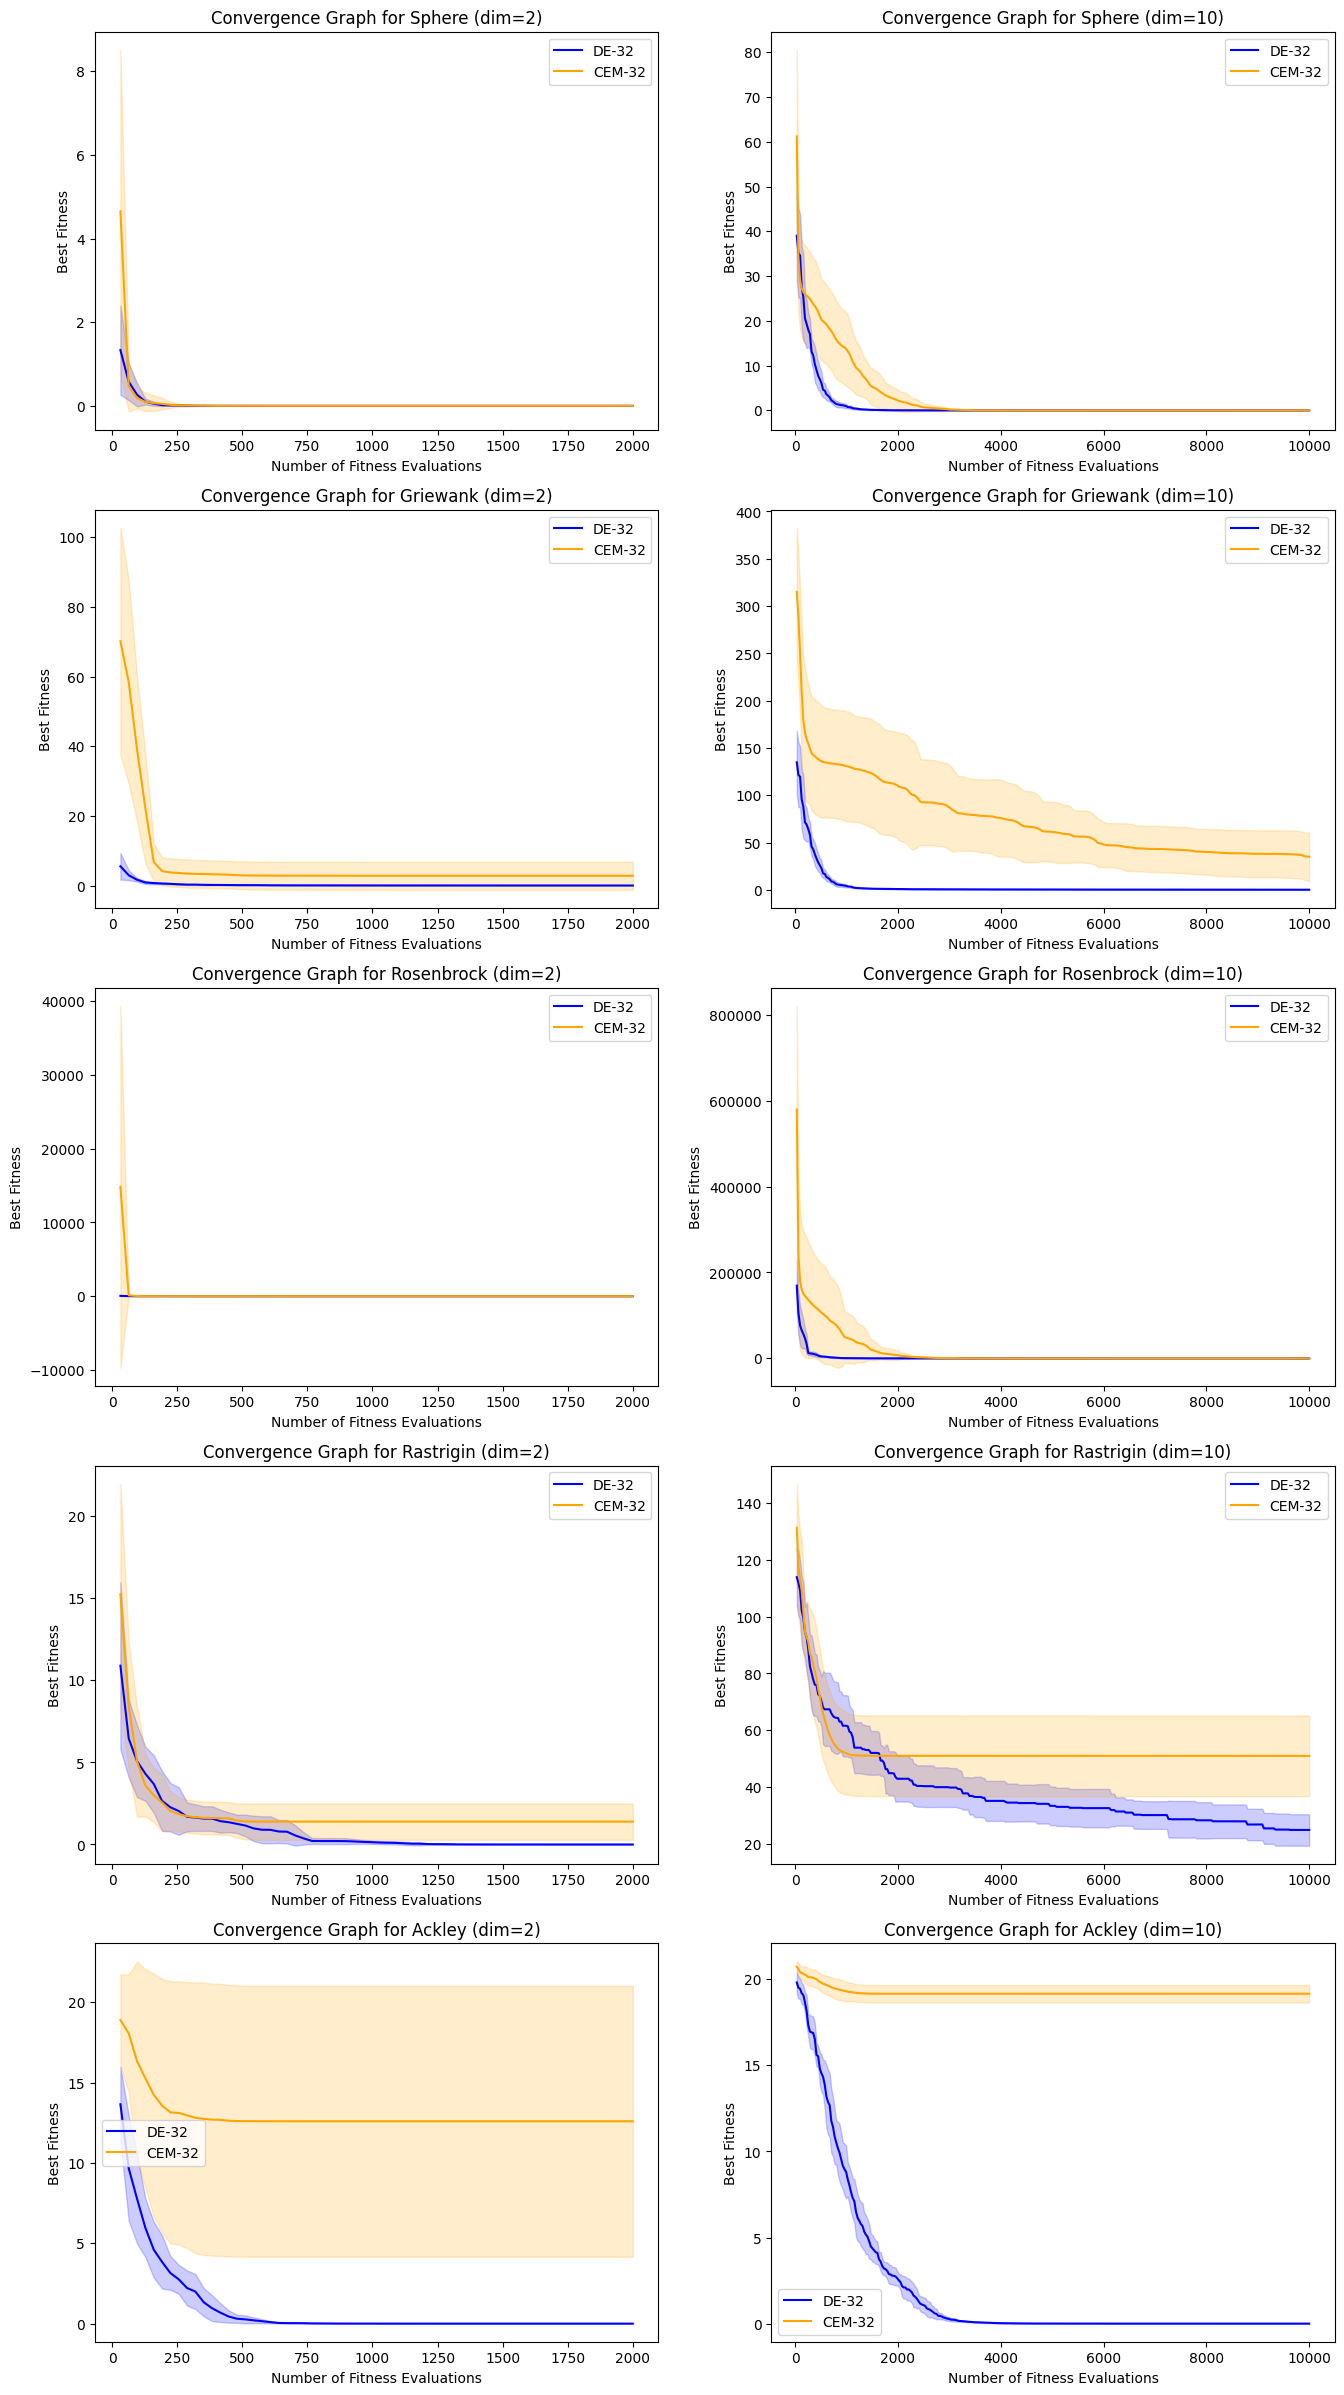

In [20]:
rows = len(obj_funcs)
cols = len(POSSIBLE_DIMS)
fig, axs = plt.subplots(rows, cols, figsize=(cols * 8, rows * 6))
for r, obj_func_name in enumerate(obj_funcs.keys()):
    for c, dim in enumerate(POSSIBLE_DIMS):
        ax = axs[r, c]
        for algo in ["DE", "CEM"]:
            color = "blue" if algo == "DE" else "orange"
            evals, mean, std = convergence_graph[(obj_func_name, dim)][algo]
            ax.plot(
                evals,
                mean,
                label=f"{algo}-{GRAPH_N}",
                color=color,
            )
            ax.fill_between(
                evals,
                mean - std,
                mean + std,
                alpha=0.2,
                color=color,
            )
        ax.set_xlabel("Number of Fitness Evaluations")
        ax.set_ylabel("Best Fitness")
        ax.set_title(f"Convergence Graph for {obj_func_name} (dim={dim})")
        ax.legend()

plt.show()

# 4.3. GIFs


In [21]:
dim_gif = 2
pop_size_gif = 32
random_seed_gif = STUDENT_ID
max_evals_gif = 5000

In [22]:
for obj_func_name, obj_func in obj_funcs.items():
    print(f"Processing GIFs for {obj_func_name}...")

    # Run DE
    eval_list_de, fitness_list_de, best_fitness_de, history_de = differential_evo(
        obj_func=obj_func,
        pop_size=pop_size_gif,
        dim=dim_gif,
        max_evals=max_evals_gif,
        random_seed=random_seed_gif,
        return_history=True,
    )
    print(
        f"DE - Best Fitness: {best_fitness_de:.6f}, Distance to optimum: {abs(best_fitness_de - obj_func.evaluate(obj_func.get_global_minimum(dim_gif).reshape(1, dim_gif))[0]):.6f}"
    )
    create_gif(obj_func_name, obj_func, history_de, "DE")

    # Run CEM
    eval_list_cem, fitness_list_cem, best_fitness_cem, history_cem = (
        cross_entropy_method(
            obj_func=obj_func,
            pop_size=pop_size_gif,
            dim=dim_gif,
            max_evals=max_evals_gif,
            random_seed=random_seed_gif,
            return_history=True,
        )
    )
    print(
        f"CEM - Best Fitness: {best_fitness_cem:.6f}, Distance to optimum: {abs(best_fitness_cem - obj_func.evaluate(obj_func.get_global_minimum(dim_gif).reshape(1, dim_gif))[0]):.6f}"
    )
    create_gif(obj_func_name, obj_func, history_cem, "CEM")

Processing GIFs for Sphere...
DE - Best Fitness: 0.000000, Distance to optimum: 0.000000
CEM - Best Fitness: 0.000000, Distance to optimum: 0.000000
Processing GIFs for Griewank...
DE - Best Fitness: 0.000000, Distance to optimum: 0.000000
CEM - Best Fitness: 0.848115, Distance to optimum: 0.848115
Processing GIFs for Rosenbrock...
DE - Best Fitness: 0.000000, Distance to optimum: 0.000000
CEM - Best Fitness: 0.000002, Distance to optimum: 0.000002
Processing GIFs for Rastrigin...
DE - Best Fitness: 0.000000, Distance to optimum: 0.000000
CEM - Best Fitness: 0.994960, Distance to optimum: 0.994960
Processing GIFs for Ackley...
DE - Best Fitness: 0.000000, Distance to optimum: 0.000000
CEM - Best Fitness: 19.761029, Distance to optimum: 19.761029


# 5. Statistics


In [23]:
for obj_func_name in obj_funcs.keys():
    print(f"\n{'='*80}")
    print(f"STATISTICS FOR: {obj_func_name}")
    print(f"{'='*80}")

    for dim in POSSIBLE_DIMS:
        print(f"\nDIMENSION: {dim}")
        print(f"|{'-'*12}-{'-'*32}-{'-'*32}-{'-'*15}|")
        print(f"| {'Pop Size':<10} | {'DE':<30} | {'CEM':<30} | {'p-value':<13} |")
        print(f"|{'-'*12}|{'-'*32}|{'-'*32}|{'-'*15}|")

        for pop_size in POSSIBLE_POP_SIZES:
            de_stats = statistic_table[(obj_func_name, dim, pop_size)]["DE"]
            cem_stats = statistic_table[(obj_func_name, dim, pop_size)]["CEM"]

            de_str = f"{de_stats['mean']:.4f} ({de_stats['std']:.4f})"
            cem_str = f"{cem_stats['mean']:.4f} ({cem_stats['std']:.4f})"

            # Round statistics to 4 decimal places
            de_stats["mean"] = round(de_stats["mean"], 4)
            de_stats["std"] = round(de_stats["std"], 4)
            cem_stats["mean"] = round(cem_stats["mean"], 4)
            cem_stats["std"] = round(cem_stats["std"], 4)

            # Compute t-test from statistics
            eps = 1e-12
            if de_stats["std"] == 0 and cem_stats["std"] == 0:
                p_value = 1.0 if de_stats["mean"] == cem_stats["mean"] else 0.0
            else:
                t_stat, p_value = ttest_ind_from_stats(
                    mean1=de_stats["mean"],
                    std1=de_stats["std"] + eps,
                    nobs1=N_TRIALS,
                    mean2=cem_stats["mean"],
                    std2=cem_stats["std"] + eps,
                    nobs2=N_TRIALS,
                    equal_var=False,  # Welch's t-test
                )

            if p_value < 0.05:
                if de_stats["mean"] < cem_stats["mean"]:
                    de_str = f"{de_str} *"
                else:
                    cem_str = f"{cem_str} *"

            print(
                f"| {pop_size:<10d} | {de_str:<30} | {cem_str:<30} | {p_value:<13.4e} |"
            )

        print(f"|{'-'*12}-{'-'*32}-{'-'*32}-{'-'*15}|")


STATISTICS FOR: Sphere

DIMENSION: 2
|----------------------------------------------------------------------------------------------|
| Pop Size   | DE                             | CEM                            | p-value       |
|------------|--------------------------------|--------------------------------|---------------|
| 8          | 0.0014 (0.0040)                | 0.0000 (0.0000)                | 2.9709e-01    |
| 16         | 0.0000 (0.0000)                | 0.0000 (0.0000)                | 1.0000e+00    |
| 32         | 0.0000 (0.0000)                | 0.0000 (0.0000)                | 1.0000e+00    |
| 64         | 0.0000 (0.0000)                | 0.0000 (0.0000)                | 1.0000e+00    |
| 128        | 0.0000 (0.0000)                | 0.0000 (0.0000)                | 1.0000e+00    |
|----------------------------------------------------------------------------------------------|

DIMENSION: 10
|-------------------------------------------------------------------------